<a href="https://colab.research.google.com/github/gloria-mbilinyi/gloria-mbilinyi-COU07506-labs/blob/main/COU07506_Week01_240242493088.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WEEK 1 — LAB 0: SETTING UP THE DSP LABORATORY

**Student Name:** Gloria Beneth Mbilinyi  
**Registration Number:** 240242493088  
**Week:** 01  
**Group:** 08  
**Date:** 23/11/2026  
**Module:** COU 07506 — Digital Signal Processing  
**Academic Year:** 2026/2027

### Laboratory Objectives

1. Set up and become familiar with the Python-based DSP laboratory environment.
2. Generate and visualize elementary discrete-time signals.
3. Investigate how changing signal parameters affects signal behaviour.
4. Record, import, normalize, plot, and play an audio signal.
5. Become familiar with basic signal processing tools used in Python and GNU Octave.

Task 1.1 — **Elementary discrete-time sequences**

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)
print("Libraries imported successfully.")

Libraries imported successfully.


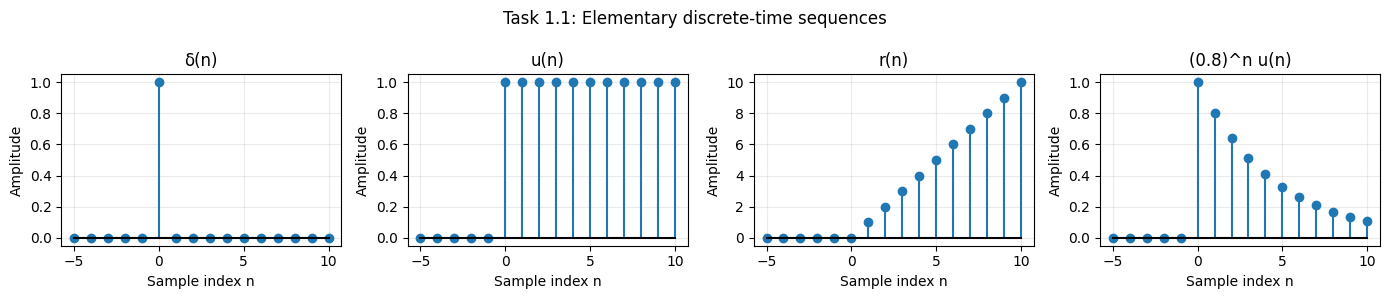

Task 1.1: all sequence checks passed.


In [ ]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)   # unit impulse
step = (n >= 0).astype(float)    # unit step
ramp = n * step                 # unit ramp
expo = 0.8**n * step             # right-sided exponential

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                         ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("Sample index n")
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.25)
fig.suptitle("Task 1.1: Elementary discrete-time sequences")
plt.tight_layout()
plt.show()

assert delta[n == 0].item() == 1 and delta.sum() == 1
assert np.all(step[n < 0] == 0) and np.all(step[n >= 0] == 1)
assert np.all(ramp[n < 0] == 0)
assert np.allclose(expo[n >= 0], 0.8**n[n >= 0])
print("Task 1.1: all sequence checks passed.")

**Observation**: The impulse is nonzero only at n = 0; the step becomes 1 at n = 0; the ramp increases from zero; and (0.8)^n u(n) decays towards zero for non negative n.

Task 1.2 — **Change the parameters**


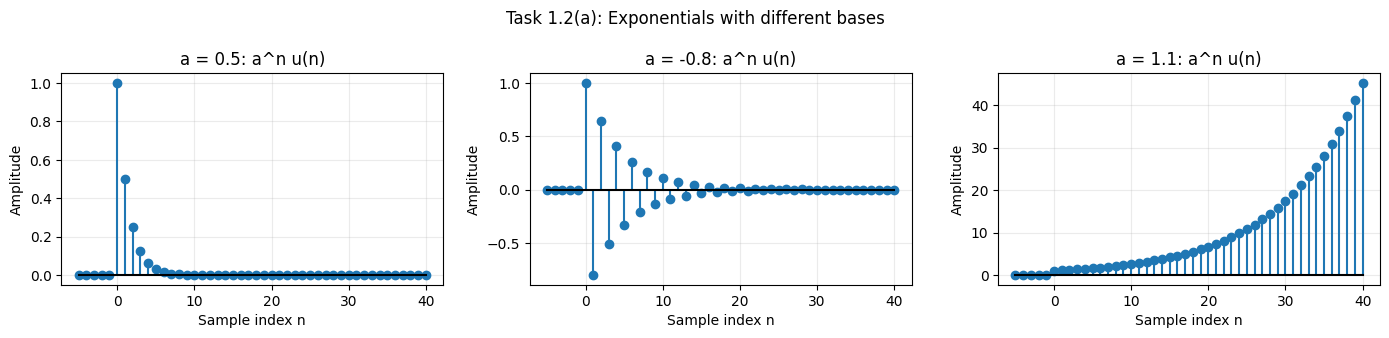

In [ ]:
n = np.arange(-5, 41)
u = (n >= 0).astype(float)
a_values = [0.5, -0.8, 1.1]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, a in zip(axes, a_values):
    x = (a**n) * u
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a = {a}: a^n u(n)")
    ax.set_xlabel("Sample index n")
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.25)
fig.suptitle("Task 1.2(a): Exponentials with different bases")
plt.tight_layout()
plt.show()

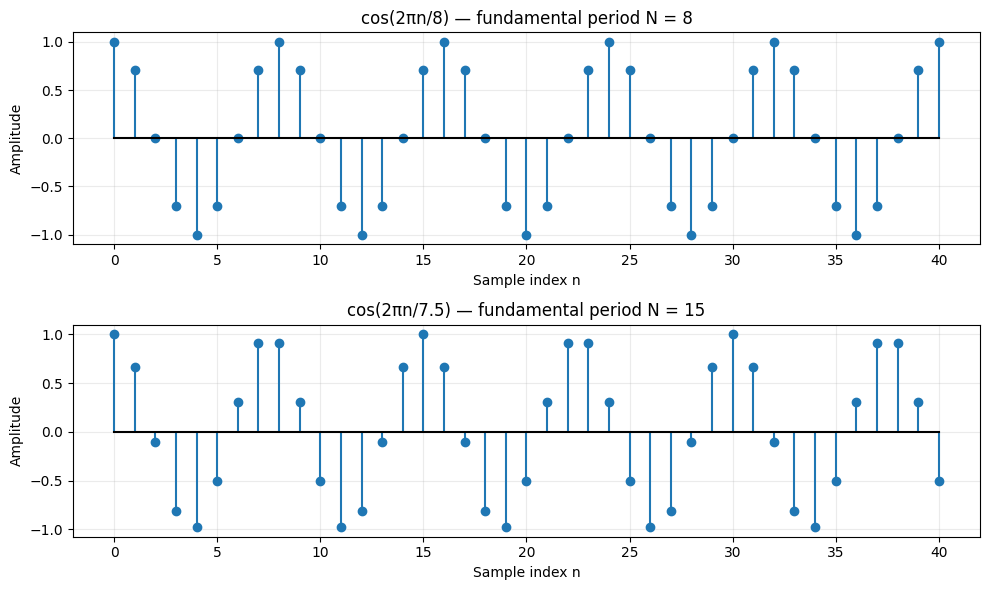

Both sequences repeat exactly: periods 8 and 15 samples, respectively.


In [ ]:
n = np.arange(0, 41)
x8 = np.cos(2*np.pi*n/8)
x75 = np.cos(2*np.pi*n/7.5)
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
axes[0].stem(n, x8, basefmt="k-")
axes[0].set_title("cos(2πn/8) — fundamental period N = 8")
axes[1].stem(n, x75, basefmt="k-")
axes[1].set_title("cos(2πn/7.5) — fundamental period N = 15")
for ax in axes:
    ax.set_xlabel("Sample index n")
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
assert np.allclose(x8[:-8], x8[8:])
assert np.allclose(x75[:-15], x75[15:])
print("Both sequences repeat exactly: periods 8 and 15 samples, respectively.")

**Task 1.2 observations:** a = 0.5 gives positive decay, a = -0.8 gives alternating-sign decay, and a = 1.1 gives growth. Both cosine sequences are discrete-time periodic, despite the decimal 7.5: cos(2πn/8) repeats after 8 samples; cos(2πn/7.5) = cos(2π(2/15)n) repeats after 15 samples, because the normalized frequency 2/15 is rational.

**Task 1.3 — Working with audio**

In [ ]:

from google.colab import files
import subprocess

# Upload your M4A recording
uploaded = files.upload()

# Get the uploaded filename
filename = next(iter(uploaded))

# Convert M4A to WAV
subprocess.run([
    "ffmpeg", "-y",
    "-i", filename,
    "-ac", "1",
    "-ar", "44100",
    "my_voice.wav"
], check=True)

print("Conversion successful: my_voice.wav")


Saving WhatsApp Audio 2026-11-23 at 21.38.20.mp4 to WhatsApp Audio 2026-11-23 at 21.38.20.mp4
Conversion successful: my_voice.wav


**TO TEST THE FUNCTIONALITY OF WAV**

In [ ]:

from scipy.io import wavfile
from IPython.display import Audio, display
import numpy as np

# Read the converted WAV file
fs, x = wavfile.read("my_voice.wav")

# Trim the recording to 5 seconds
x = x[:5 * fs]

# Save the trimmed recording
wavfile.write("my_voice_5sec.wav", fs, x)

# Display audio information
print("Sampling rate:", fs, "Hz")
print("Duration:", len(x) / fs, "seconds")
print("Total samples:", len(x))

# Play the 5-second recording
display(Audio(x, rate=fs))


Sampling rate: 44100 Hz
Duration: 5.0 seconds
Total samples: 220500


Sampling rate: 44100 Hz
Duration: 5.0 seconds
Number of samples: 220500


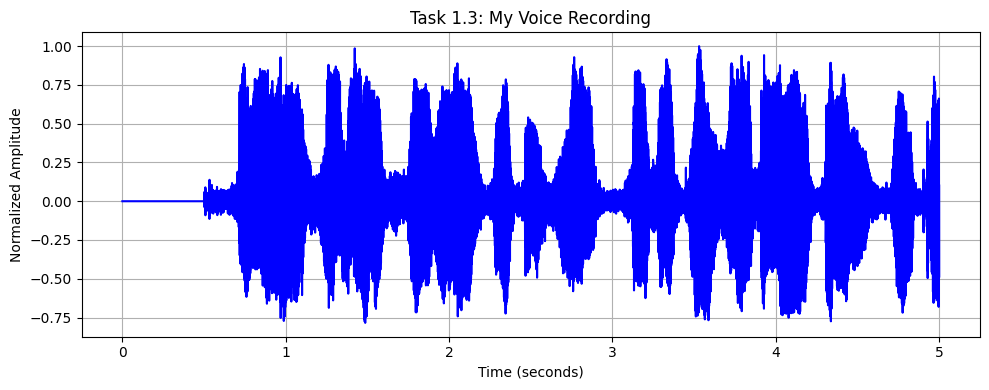

In [ ]:

# Task 1.3: Working with Audio

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio, display

# Read the trimmed 5-second WAV audio file
fs, x = wavfile.read("my_voice_5sec.wav")

# Convert stereo to mono if necessary
if x.ndim > 1:
    x = x.mean(axis=1)

# Normalize the audio signal
x = x.astype(float)
x = x / np.max(np.abs(x))

# Generate the time axis
t = np.arange(len(x)) / fs

# Display audio information
print("Sampling rate:", fs, "Hz")
print("Duration:", round(len(x) / fs, 2), "seconds")
print("Number of samples:", len(x))

# Plot the audio waveform
plt.figure(figsize=(10, 4))
plt.plot(t, x, color="blue")

plt.title("Task 1.3: My Voice Recording")
plt.xlabel("Time (seconds)")
plt.ylabel("Normalized Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()

# Play the 5-second voice recording
display(Audio(x, rate=fs))


**### Task 1.3: Results and Discussion**

I successfully converted my voice recording into WAV format and processed it using Python in Google Colab.

The recording has a sampling rate of 44,100 Hz, a duration of 5 seconds, and a total of 220,500 samples.

The waveform shows how the amplitude of my voice changes with time. The larger peaks represent louder parts of my speech, while the smaller amplitudes represent quieter parts or pauses.

The signal was normalized, plotted in the time domain, and successfully played back using the IPython Audio function.

**Task 1.4 — The Same in GNU Octave**



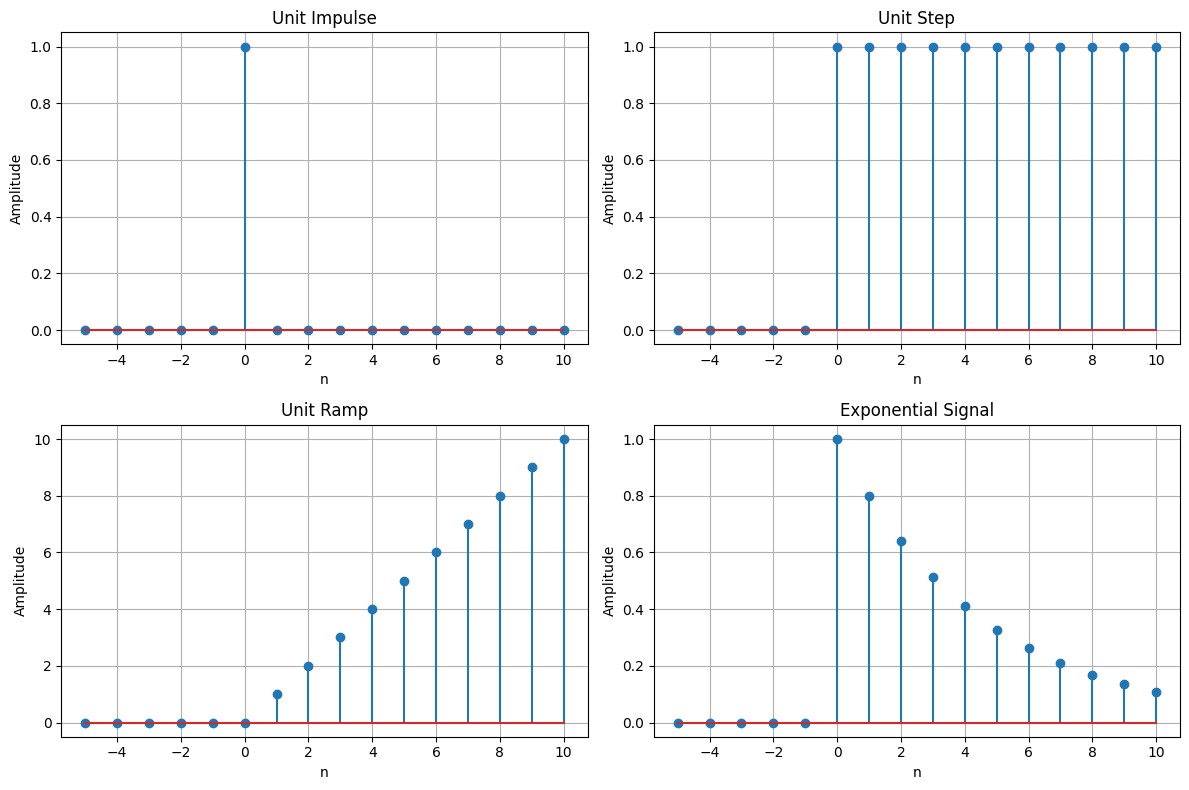

In [ ]:

# Task 1.4: Discrete-Time Signals using Python

import numpy as np
import matplotlib.pyplot as plt

# Define discrete-time indices
n = np.arange(-5, 11)

# Unit impulse
delta = (n == 0).astype(float)

# Unit step
u = (n >= 0).astype(float)

# Unit ramp
r = n * u

# Exponential signal
expo = (0.8 ** n) * u

# Create four subplots
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.stem(n, delta)
plt.title("Unit Impulse")
plt.xlabel("n")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(2, 2, 2)
plt.stem(n, u)
plt.title("Unit Step")
plt.xlabel("n")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(2, 2, 3)
plt.stem(n, r)
plt.title("Unit Ramp")
plt.xlabel("n")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(2, 2, 4)
plt.stem(n, expo)
plt.title("Exponential Signal")
plt.xlabel("n")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()


### Task 1.4: Results and Discussion

The four discrete-time signals were successfully generated and plotted.

1. **Unit Impulse:** The signal has an amplitude of 1 at n = 0 and 0 at all other indices.
2. **Unit Step:** The signal is 0 for negative indices and becomes 1 at n = 0.
3. **Unit Ramp:** The signal increases linearly from n = 0.
4. **Exponential Signal:** The signal starts at 1 and gradually decreases toward zero because the base is 0.8, which is less than 1.

All four signals were displayed using stem plots because they are discrete-time signals defined at integer sample indices.



# WEEK 1 — PRE-LAB AND ANALYSIS QUESTIONS



## A. PRE-LAB QUESTION

**Question: List three devices you used today that contain DSP, and for each name one signal it processes.**

**Answer:**

1. **Smartphone:** Processes voice/audio signals during phone calls, voice recordings, and music playback.
2. **Laptop:** Processes digital audio signals during video calls and multimedia playback.
3. **Wireless Earphones:** Process audio signals for sound reproduction and noise reduction.

These devices use Digital Signal Processing to improve the quality and processing of signals.

## B. ANALYSIS QUESTIONS

### Question 1: What is the sampling rate of your phone's recording? How many numbers are needed to store one minute of it in mono?

**Answer:**

The sampling rate of my converted WAV recording is **44,100 Hz**, meaning 44,100 samples are represented every second.

The number of samples required for one minute is calculated as:

Number of samples = Sampling rate × Duration

= 44,100 × 60

= **2,646,000 samples**

Therefore, one minute of mono audio recorded at 44,100 Hz requires 2,646,000 sample values.

### Question 2: Why is a stem plot more appropriate than a continuous line for x(n)?

**Answer:**

A stem plot is more appropriate because x(n) is a discrete-time signal. It is defined only at specific integer values of n.

A stem plot displays each sample separately, while a continuous line may incorrectly suggest that the signal exists at every point between samples.

Therefore, stem plots provide a more accurate representation of discrete-time signals.

### Question 3: For a = 1.1, the exponential grows. Which property of a system would such a signal violate if it were an impulse response?

**Answer:**

If the exponentially growing signal were an impulse response, it would violate the **Bounded-Input Bounded-Output (BIBO) stability** property of an LTI system.

For an LTI system to be BIBO stable, its impulse response must be absolutely summable.

Since h(n) = (1.1)^n u(n) increases without bound, the sum of its absolute values does not converge.

Therefore, the system would be unstable.

## C. CONCLUSION

In this laboratory, I learned how to generate and plot discrete-time signals using Python. I also observed how changing the parameters affects exponential and cosine signals.

I successfully processed my voice recording using Google Colab. The final WAV recording had a sampling rate of 44,100 Hz, a duration of 5 seconds, and 220,500 samples.

This laboratory helped me understand basic discrete-time signals, sampling, signal visualization, and audio processing.

## D. AI-USE STATEMENT

I used ChatGPT to help explain Python code, troubleshoot errors, and understand the laboratory tasks. I checked the results by running the code in Google Colab and examining the generated plots and audio output.